In [1]:
from pyaedt import Q3d
from pyaedt.generic.constants import PLANE
from ansys.aedt.core.q3d import Q3d

In [2]:
my_path = r"D:\Users\QDG\Nimisha\unit_cell_tests\unit_cell_q3d\bleh.aedt"
#need to change above line so that operate.py works...
q3d = Q3d(version="2024.1", non_graphical=False, close_on_exit=True)
q3d.modeler.model_units = "um"

PyAEDT INFO: Python version 3.8.20 (default, Oct  3 2024, 15:19:54) [MSC v.1929 64 bit (AMD64)]
PyAEDT INFO: PyAEDT version 0.13.3.
PyAEDT INFO: Initializing new Desktop session.
PyAEDT INFO: Log on console is enabled.
PyAEDT INFO: Log on file C:\Users\QDG-WS2\AppData\Local\Temp\pyaedt_QDG-WS2_0f57e596-189a-4942-931c-28dc4ed33240.log is enabled.
PyAEDT INFO: Log on AEDT is enabled.
PyAEDT INFO: Debug logger is disabled. PyAEDT methods will not be logged.
PyAEDT INFO: Launching PyAEDT with gRPC plugin.
PyAEDT WARNING: Multiple AEDT gRPC sessions are found. Setting the active session on port 64131
PyAEDT INFO: AEDT installation Path C:\Program Files\AnsysEM\v241\Win64
PyAEDT INFO: No project is defined. Project Project14 exists and has been read.
PyAEDT INFO: No consistent unique design is present. Inserting a new design.
PyAEDT INFO: Added design 'Q3D Extractor_KE0' of type Q3D Extractor.
PyAEDT INFO: Aedt Objects correctly read
PyAEDT INFO: Modeler class has been initialized! Elapsed t

d:\Users\QDG\Nimisha\ansys_env\lib\site-packages\ansys\aedt\core\visualization\advanced\misc.py:43: UserWarning: The PyVista module is required to run functionalities of ansys.aedt.core.visualization.advanced.misc.
Install with 

pip install pyvista
  warnings.warn(


In [3]:
# default parameters
q3d["sig_width"] = str(5) + "um"
q3d["sig_distance"] = str(100) + "um"
q3d["cap_width"] = str(13) + "um"
q3d["cap_gap"] = str(8.8) + "um"
q3d["finger_length"] = str(20) + "um"
q3d["finger_count"] = str(5)
q3d["total_added_length"] = str(150) + "um"
q3d["silicon_vacuum_thickness"] = str(675) + "um"
q3d["thickness"] = str(0.2) + "um"
q3d["mesh_length"] = str(2.5) + "um"

In [19]:
if q3d["finger_count"] != "0":

    # origin, [width, height], name
    cap_etch_north = q3d.modeler.create_rectangle(
        PLANE.XY,
        ["-(cap_width + 2 * finger_length) / 2", "sig_width / 2"],
        [
            "cap_width + 2 * finger_length",
            "2 * (finger_count * cap_width + finger_count * cap_gap)",
        ],
    )

    cap_etch_south = q3d.modeler.create_rectangle(
    PLANE.XY,
    ["-(cap_width + 2 * finger_length) / 2", "-(sig_width / 2)"],
    [
        "cap_width + 2 * finger_length",
        "2 * -(finger_count * cap_width + finger_count * cap_gap)",
    ])

cap_body_north = q3d.modeler.create_rectangle(
    PLANE.XY,
    ["-(cap_width + 2 * finger_length + 2 * cap_gap) / 2", "sig_width / 2"],
    [
        "cap_width + 2 * finger_length + 2 * cap_gap",
        "2 * finger_count * cap_width + (2 * finger_count + 1) * cap_gap",
    ],
)

cap_body_south = q3d.modeler.create_rectangle(
    PLANE.XY,
    ["-(cap_width + 2 * finger_length + 2 * cap_gap) / 2", "-sig_width / 2"],
    [
        "cap_width + 2 * finger_length + 2 * cap_gap",
        "-(2 * finger_count * cap_width + (2 * finger_count + 1) * cap_gap)",
    ],
)

In [20]:
q3d.modeler.copy(cap_body_north)
cap_north_dup = q3d.modeler.paste()[0]
q3d.modeler.copy(cap_body_south)
cap_south_dup = q3d.modeler.paste()[0]    

if q3d["finger_count"] != "0":
    subtract_etch_north = []
    subtract_etch_south = []
    subtract_body_north = []
    subtract_body_south = []


    for i in range(int(q3d.evaluate_expression("finger_count"))):

        body_north_left = q3d.modeler.create_rectangle(
            PLANE.XY,
            [
                "-(cap_width + 2 * finger_length + 2 * cap_gap) / 2",
                "((sig_width / 2 + cap_gap) + 2 *" + str(i) + "* (cap_width + cap_gap))",
            ],
            ["finger_length", "cap_width"],
        )

        body_north_right = q3d.modeler.create_rectangle(
            PLANE.XY,
            [
                "(cap_width + 2 * finger_length + 2 * cap_gap) / 2",
                "((sig_width / 2 + cap_gap) + 2 *" + str(i) + "* (cap_width + cap_gap))",
            ],
            ["-finger_length", "cap_width"],
        )

        body_south_left = q3d.modeler.create_rectangle(
            PLANE.XY,
            [
                "-(cap_width + 2 * finger_length + 2 * cap_gap) / 2",
                "-((sig_width / 2 + cap_gap) + 2 *" + str(i) + "* (cap_width + cap_gap))",
            ],
            ["finger_length", "-cap_width"],
        )

        body_south_right = q3d.modeler.create_rectangle(
            PLANE.XY,
            [
                "(cap_width + 2 * finger_length + 2 * cap_gap) / 2",
                "-((sig_width / 2 + cap_gap) + 2 *" + str(i) + "* (cap_width + cap_gap))",
            ],
            ["-finger_length", "-cap_width"],
        )

        rect_north_left = q3d.modeler.create_rectangle(
            PLANE.XY,
            [
                "-(cap_width + 2 * finger_length) / 2",
                "(2 *" + str(i) + ") * cap_gap + sig_width / 2 + (2 *" + str(i) + ") * cap_width",
            ],
            ["finger_length", "2 * cap_gap + cap_width"],
        )

        rect_north_right = q3d.modeler.create_rectangle(
            PLANE.XY,
            ["(cap_width) / 2", "(2 *" + str(i) + ") * cap_gap + sig_width / 2 + (2 *" + str(i) + ") * cap_width"],
            ["finger_length", "2 * cap_gap + cap_width"],
        )

        rect_south_left = q3d.modeler.create_rectangle(
            PLANE.XY,
            [
                "-(cap_width + 2 * finger_length) / 2",
                "-((2 *" + str(i) + ") * cap_gap + sig_width / 2 + (2 *" + str(i) + ") * cap_width)"],
            ["finger_length", "-(2 * cap_gap + cap_width)"],
        )

        rect_south_right = q3d.modeler.create_rectangle(
            PLANE.XY,
            ["(cap_width) / 2", "-((2 *" + str(i) + ") * cap_gap + sig_width / 2 + (2 *" + str(i) + ") * cap_width)"],
            ["finger_length", "-(2 * cap_gap + cap_width)"],
        )

        subtract_body_north.append(body_north_left)
        subtract_body_north.append(body_north_right)
        subtract_body_south.append(body_south_left)
        subtract_body_south.append(body_south_right)
        subtract_etch_north.append(rect_north_left)
        subtract_etch_north.append(rect_north_right)
        subtract_etch_south.append(rect_south_left)
        subtract_etch_south.append(rect_south_right)

  

In [21]:
q3d.modeler.subtract(cap_etch_north, subtract_etch_north, False)
q3d.modeler.subtract(cap_etch_south, subtract_etch_south, False)
q3d.modeler.subtract(cap_body_north, subtract_body_north, False)
q3d.modeler.subtract(cap_body_south, subtract_body_south, False)


PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec


True

In [ ]:
# creating a duplicate body for the vacuum
q3d.modeler.copy(cap_etch_north)
cap_etch_dup = q3d.modeler.paste()[0]
q3d.modeler.subtract(cap_north_dup, cap_etch_dup, False)


q3d.modeler.copy(cap_etch_south)
cap_etch_dup2 = q3d.modeler.paste()[0]
q3d.modeler.subtract(cap_south_dup, cap_etch_dup2, False)


total_etch = q3d.modeler.unite([cap_etch_north, cap_etch_south])

PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Union of 2 objects has been executed.


In [ ]:
# creating the outside of the final unit cell
final_unit_cell_north = q3d.modeler.create_rectangle(
    PLANE.XY,
    ["-(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", "sig_width / 2"],
    [
        "cap_width * 3 + 2 * finger_length + 2 * cap_gap",
        "total_added_length + (2 * finger_count * cap_width + (2 * finger_count + 1) * cap_gap)",
    ],
)
final_unit_cell_south = q3d.modeler.create_rectangle(
    PLANE.XY,
    [
        "-(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2",
        "-sig_width / 2",
    ],
    [     "cap_width * 3 + 2 * finger_length + 2 * cap_gap",
        "-total_added_length - (2 * finger_count * cap_width + (2 * finger_count + 1) * cap_gap)"
        ,
    ],
)
q3d.modeler.subtract(final_unit_cell_north, cap_body_north, False)
q3d.modeler.subtract(final_unit_cell_south, cap_body_south, False)
q3d.modeler.subtract(cap_north_dup, final_unit_cell_north, True)
q3d.modeler.subtract(cap_south_dup, final_unit_cell_south, True)


PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec


True

True

In [32]:
### center part was being weird so it is manually fixed here
annoying_rectangles_north = [
    q3d.modeler.create_rectangle(
        PLANE.XY,
        ["-(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", "sig_width / 2"],
        ["cap_width", "cap_gap"],
    ),
    q3d.modeler.create_rectangle(
        PLANE.XY,
        ["(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", "sig_width / 2"],
        ["-cap_width", "cap_gap"],
    ),
]

annoying_rectangles_south = [
    q3d.modeler.create_rectangle(
        PLANE.XY,
        ["-(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", "-sig_width / 2"],
        ["cap_width", "-cap_gap"],
    ),
    q3d.modeler.create_rectangle(
        PLANE.XY,
        ["(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", "-sig_width / 2"],
        ["-cap_width", "-cap_gap"],
    ),
]

# #creating vacuums for the annoying rectangles
annoying_rectangles_north_copy = [
    q3d.modeler.create_rectangle(
        PLANE.XY,
        ["-(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", "sig_width / 2"],
        ["cap_width", "cap_gap"],
    ),
    q3d.modeler.create_rectangle(
        PLANE.XY,
        ["(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", "sig_width / 2"],
        ["-cap_width", "cap_gap"],
    ),
]

annoying_rectangles_south_copy = [
    q3d.modeler.create_rectangle(
        PLANE.XY,
        ["-(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", "-sig_width / 2"],
        ["cap_width", "-cap_gap"],
    ),
    q3d.modeler.create_rectangle(
        PLANE.XY,
        ["(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", "-sig_width / 2"],
        ["-cap_width", "-cap_gap"],
    ),
]



In [33]:
# creating silicon and vacuum blocks
vacuum = q3d.modeler.create_box(["-(cap_width * 3 + 2 * finger_length + 2 * cap_gap)/2",
        "-(total_added_length + sig_width/2 + (2 * finger_count * cap_width + (2 * finger_count + 1) * cap_gap))", "thickness/2"], 
        ["cap_width * 3 + 2 * finger_length + 2 * cap_gap",
        "2*(total_added_length + sig_width/2 + (2 * finger_count * cap_width + (2 * finger_count + 1) * cap_gap))", "silicon_vacuum_thickness"], "vacuum", "vacuum")

silicon = q3d.modeler.create_box(["-(cap_width * 3 + 2 * finger_length + 2 * cap_gap)/2",
        "-(total_added_length + sig_width/2 + (2 * finger_count * cap_width + (2 * finger_count + 1) * cap_gap))", "-thickness/2"], 
        ["cap_width * 3 + 2 * finger_length + 2 * cap_gap",
        "2*(total_added_length + sig_width/2 + (2 * finger_count * cap_width + (2 * finger_count + 1) * cap_gap))", "-silicon_vacuum_thickness"], "silicon", "silicon")


q3d.modeler.subtract(final_unit_cell_north, annoying_rectangles_north, False)
q3d.modeler.subtract(final_unit_cell_south, annoying_rectangles_south, False)


center = q3d.modeler.create_rectangle(
    PLANE.XY,
    ["-(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", "-sig_width / 2"],
    ["cap_width * 3 + 2 * finger_length + 2 * cap_gap", "sig_width"],
)

if q3d["finger_count"] != "0":
    total_etch = q3d.modeler.unite([center, total_etch])


PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Union of 2 objects has been executed.


In [34]:
q3d.modeler.thicken_sheet(final_unit_cell_north, "thickness", both_sides=True)
q3d.modeler.thicken_sheet(final_unit_cell_south, "thickness", both_sides=True)

if q3d["finger_count"] != "0":
    q3d.modeler.thicken_sheet(total_etch, "thickness",both_sides=True)
    
    q3d.assign_material(
        [final_unit_cell_north, final_unit_cell_south, total_etch], "perfect conductor")
else:
    q3d.modeler.thicken_sheet(center, "thickness",both_sides=True)
    
    q3d.assign_material(
        [final_unit_cell_north, final_unit_cell_south, center], "perfect conductor")


final_unit_cell_south.rotate(1, 180)

In [35]:

q3d.assign_net(final_unit_cell_north, "North")
q3d.sink(
    q3d.modeler.get_faceid_from_position(
        ["(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", "((total_added_length + (2 * finger_count * cap_width + (2 * finger_count + 1) * cap_gap)) - (cap_gap - sig_width/2))/2 + cap_gap", 0],
        final_unit_cell_north,
    ),
    net_name="North",
)

q3d.source(
    q3d.modeler.get_faceid_from_position(
        ["-(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", "((total_added_length + (2 * finger_count * cap_width + (2 * finger_count + 1) * cap_gap)) - (cap_gap - sig_width/2))/2 + cap_gap", 0],
        final_unit_cell_north,
    ),
    net_name="North",
)

q3d.assign_net(final_unit_cell_south, "South")
q3d.sink(
    q3d.modeler.get_faceid_from_position(
        ["(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", "-((total_added_length + (2 * finger_count * cap_width + (2 * finger_count + 1) * cap_gap)) - (cap_gap - sig_width/2))/2 + cap_gap", 0],
        final_unit_cell_south,
    ),
    net_name="South",
)

q3d.source(
    q3d.modeler.get_faceid_from_position(
        ["-(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", "-((total_added_length + (2 * finger_count * cap_width + (2 * finger_count + 1) * cap_gap)) - (cap_gap - sig_width/2))/2 + cap_gap", 0],
        final_unit_cell_south,
    ),
    net_name="South",
)


if q3d["finger_count"] != "0":
    q3d.assign_net(total_etch, "Etch")
    q3d.sink(
        q3d.modeler.get_faceid_from_position(
             ["(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", 0, 0],
             total_etch,
         ),
         net_name="Etch",
     )
    q3d.source(
         q3d.modeler.get_faceid_from_position(
             ["-(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", 0, 0],
             total_etch,
         ),
         net_name="Etch",
     )
    q3d.mesh.assign_length_mesh(
         [total_etch, final_unit_cell_north, final_unit_cell_south], maximum_length="mesh_length")
else:
    q3d.assign_net(center, "Etch")
    q3d.sink(
         q3d.modeler.get_faceid_from_position(
             ["(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", 0, 0],
             center,
         ),
         net_name="Etch",
     )
    q3d.source(
         q3d.modeler.get_faceid_from_position(
             ["-(cap_width * 3 + 2 * finger_length + 2 * cap_gap) / 2", 0, 0],
             center,
         ),
         net_name="Etch",
     )

    q3d.mesh.assign_length_mesh(
         [center, final_unit_cell_north, final_unit_cell_south], maximum_length="mesh_length")


In [36]:
# Thicken vacuums
q3d.modeler.thicken_sheet(cap_north_dup, "thickness", both_sides=True)
q3d.modeler.thicken_sheet(cap_south_dup, "thickness", both_sides=True)
q3d.assign_material([cap_north_dup, cap_south_dup], "vacuum")
q3d.modeler.thicken_sheet(annoying_rectangles_north_copy, "thickness", both_sides=True)
q3d.modeler.thicken_sheet(annoying_rectangles_south_copy, "thickness", both_sides=True)
q3d.assign_material(annoying_rectangles_north_copy, "vacuum")
q3d.assign_material(annoying_rectangles_south_copy, "vacuum")

True

In [9]:
q3d = Q3d(specified_version="2024.1", non_graphical=False, close_on_exit=True)
# my_path = r"D:\Users\QDG\Nimisha\unit_cell_tests\CPW_finer\testCell0.aedt"
# q3d.load_project(my_path)

PyAEDT WARNING: Argument `specified_version` is deprecated for method `__init__`; use `version` instead.
PyAEDT INFO: Python version 3.8.20 (default, Oct  3 2024, 15:19:54) [MSC v.1929 64 bit (AMD64)]
PyAEDT INFO: PyAEDT version 0.13.3.
PyAEDT INFO: Initializing new Desktop session.
PyAEDT INFO: Log on console is enabled.
PyAEDT INFO: Log on file C:\Users\QDG-WS2\AppData\Local\Temp\pyaedt_QDG-WS2_3fcaf7dc-bce5-4311-a897-3b9bf5bbee0f.log is enabled.
PyAEDT INFO: Log on AEDT is enabled.
PyAEDT INFO: Debug logger is disabled. PyAEDT methods will not be logged.
PyAEDT INFO: Launching PyAEDT with gRPC plugin.
PyAEDT INFO: Found active AEDT gRPC session on port 50051
PyAEDT INFO: AEDT installation Path C:\Program Files\AnsysEM\v241\Win64
PyAEDT INFO: No project is defined. Project testCell0 exists and has been read.
PyAEDT INFO: Active Design set to Q3D Extractor_3RK
PyAEDT INFO: Aedt Objects correctly read


In [12]:
setup = q3d.create_setup()
variable_sweeps = q3d.parametrics

### CHANGE SWEEP VARIABLES HERE
variable_sweeps.add("sig_width", 5, 55, 10)

# print(setup.props)
setup.props["DC"] = True
setup.props["AdaptiveFreq"] = ["5GHz"]
setup.props["Cap"]["PerRefine"] = 30
setup.props["Cap"]["MaxPass"] = 20
setup.props["Cap"]["MinPass"] = 5
setup.props["Cap"]["PerError"] = 1
setup.props["AC"]["PerRefine"] = 30
setup.props["AC"]["MaxPass"] = 20
setup.props["AC"]["MinPass"] = 5
setup.props["AC"]["PerError"] = 1
setup.add_sweep()

setup.update

q3d.analyze()
q3d.save_project(my_path)

PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/Q3D Extractor correctly changed.
PyAEDT INFO: Solving all design setups.
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/Q3D Extractor correctly changed.
PyAEDT INFO: Design setup None solved correctly in 0.0h 7.0m 6.0s
PyAEDT INFO: Project testCell0 Saved correctly


True

In [10]:
all_variations = q3d.available_variations.variations()
import re
def clean_value(val):
    """Clean a float-like string and return compact representation, e.g. '0.20000000000000001um' -> '0.2um'"""
    match = re.match(r"([0-9.]+)([a-zA-Z]*)", val)
    if match:
        num, unit = match.groups()
        try:
            num_clean = str(round(float(num), 6))  # 6 decimal digits max
        except ValueError:
            num_clean = num
        return f"{num_clean}{unit}"
    return val
def variation_list_to_string(var_list):
    """Converts a list of name/value pairs into an Ansys-style variation string"""
    # Create a dictionary from the list
    var_dict = {}
    for i in range(0, len(var_list), 2):
        key = var_list[i].replace(":=", "")
        value = var_list[i + 1][0]
        var_dict[key] = clean_value(value)
    # Sort keys alphabetically for consistency
    sorted_items = sorted(var_dict.items())
    # Format into Ansys variation string
    var_string = " ".join([f"{k}='{v}'" for k, v in sorted_items])
    return var_string

all_variation_strings = [variation_list_to_string(var) for var in all_variations]

# getting the numeric paramater value of a string
def get_param_value(var_string, param_name):
    pattern = rf"{param_name}='([^']*)'"
    match = re.search(pattern, var_string)
    return match.group(1) if match else None

def get_param_numeric(var_string, param_name):
    val = get_param_value(var_string, param_name)
    if val:
        num_match = re.match(r"([0-9.]+)", val)
        return float(num_match.group(1)) if num_match else None
    return None

all_paramaters = [get_param_numeric(var, "sig_width") for var in all_variation_strings]

In [11]:
# inductance calculator
import csv
def inductance_calculator(file_path):
    with open(file_path) as csvfile:
        csv_reader = csv.reader(csvfile)
        csvr = list(csv_reader)
        i = 0
        matrix_int = []
        matrix_found = False
        while i < len(csvr):
            if matrix_found == False:
                for word in csvr[i]:
                    if (word == "AC Inductance Matrix"):
                        matrix_found = True
            else:
                j = 0
                while j < 3:
                    current_row = []
                    for k in range(len(csvr[i+j+1]) - 1):
                        current_row.append(float(csvr[i+j+1][k+1]))
                    j+=1
                    matrix_int.append(current_row)
                break
            i+=1

        L = matrix_int[0][0] - 1.5 * matrix_int[0][1] - 0.5 * matrix_int[0][2] + 0.5 * matrix_int[1][1] + 0.5 * matrix_int[1][2]
        return L
    

# capacitance calculator
def capacitance_calculator(file_path):
    with open(file_path) as csvfile:
        csv_reader = csv.reader(csvfile)
        csvr = list(csv_reader)
        i = 0
        matrix_int = []
        matrix_found = False
        while i < len(csvr):
            if matrix_found == False:
                for word in csvr[i]:
                    if (word == "Capacitance Matrix"):
                        matrix_found = True
            else:
                j = 0
                while j < 3:
                    current_row = []
                    for k in range(len(csvr[i+j+1]) - 1):
                        current_row.append(float(csvr[i+j+1][k+1]))
                    j+=1
                    matrix_int.append(current_row)
                break
            i+=1

        C = matrix_int[0][0]
        return C

In [ ]:
file_path = r"D:\Users\QDG\Nimisha\unit_cell_tests\CPW_finer\data_{}.csv".format(467)
q3d.export_matrix_data(file_path, problem_type = "AC RL", variations = all_variation_strings[1], freq = 5000000000)

In [16]:
inductance_values = []
for i in range(6):
    file_path = r"D:\Users\QDG\Nimisha\unit_cell_tests\CPW_finer\data_{}.csv".format(i)
    # q3d.export_matrix_data(file_path, problem_type = "AC RL", variations = all_variation_strings[i], freq=5000000000)
    inductance_values.append(inductance_calculator(file_path))
# q3d.save_project(my_path)
# print(all_variations)
print(inductance_values)

[0.05233285112214365, 0.04212898817769193, 0.03695819636922344, 0.03364762121729232, 0.03154514647487543, 0.029724897274969124]


In [12]:
capacitance_values = []
for i in range(6):
    file_path = r"D:\Users\QDG\Nimisha\unit_cell_tests\CPW_finer\dataC_{}.csv".format(i)
    # q3d.export_matrix_data(file_path, problem_type = "C", variations = all_variation_strings[i], freq=5, freq_unit='GHz')
    capacitance_values.append(capacitance_calculator(file_path))

print(capacitance_values)

[0.01066306284991238, 0.01354835252986239, 0.01592782642858199, 0.01701824485076674, 0.01831242335092369, 0.01981746279687899]


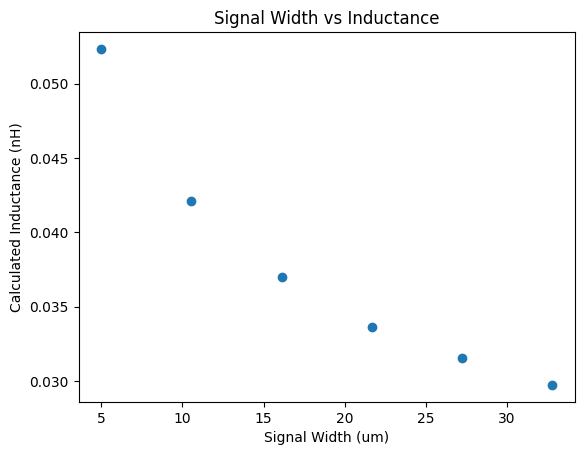

In [18]:
import numpy as np
import matplotlib.pyplot as plt
plt.scatter(all_paramaters[:6], inductance_values)
plt.xlabel("Signal Width (um)")
plt.ylabel("Calculated Inductance (nH)")
plt.title("Signal Width vs Inductance")
plt.show()

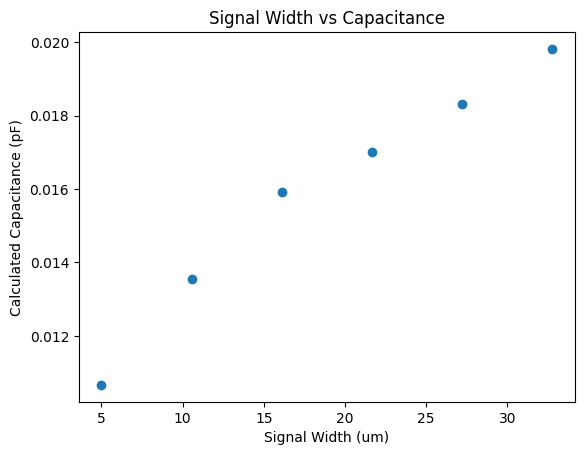

In [15]:
import numpy as np
import matplotlib.pyplot as plt
plt.scatter(all_paramaters[:6], capacitance_values)
plt.xlabel("Signal Width (um)")
plt.ylabel("Calculated Capacitance (pF)")
plt.title("Signal Width vs Capacitance")
plt.show()

In [19]:
import math
phase_velocity = []
for i in range(len(all_paramaters[:6])):
    inductance = inductance_values[i] * 10
    # print(inductance)
    capacitance = capacitance_values[i] * 10
    # print(capacitance)
    phase_velocity.append((1 / math.sqrt(inductance * capacitance) * 10 ** (21 / 2)) / (299792458 * 1000))

print(phase_velocity)

[0.4465304857148785, 0.4415150768684303, 0.43475607128093624, 0.4408031912544581, 0.4388742627905821, 0.43460537189573556]


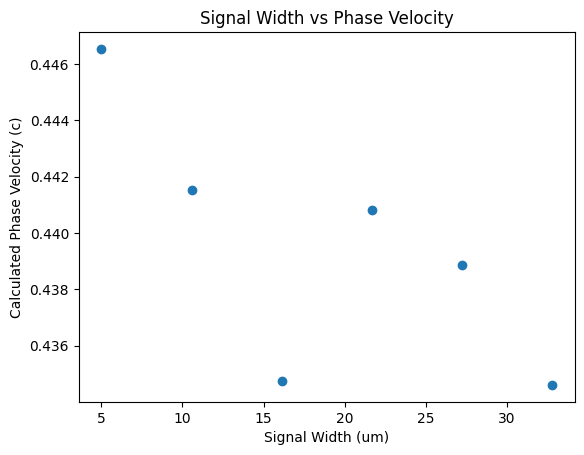

In [20]:
import numpy as np
import matplotlib.pyplot as plt
plt.scatter(all_paramaters[:6], phase_velocity)
plt.xlabel("Signal Width (um)")
plt.ylabel("Calculated Phase Velocity (c)")
plt.title("Signal Width vs Phase Velocity")
plt.show()

In [15]:
q3d.save_project(my_path)
q3d.release_desktop(close_projects=True, close_desktop=True)

PyAEDT INFO: Project testCell0 Saved correctly
PyAEDT INFO: Desktop has been released and closed.


True